In [4]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler

df = pd.read_csv('../data/credit_card.csv')

In [5]:
df = df.drop('CUST_ID', axis=1)

df.isnull().sum() 

BALANCE                               0
BALANCE_FREQUENCY                     0
PURCHASES                             0
ONEOFF_PURCHASES                      0
INSTALLMENTS_PURCHASES                0
CASH_ADVANCE                          0
PURCHASES_FREQUENCY                   0
ONEOFF_PURCHASES_FREQUENCY            0
PURCHASES_INSTALLMENTS_FREQUENCY      0
CASH_ADVANCE_FREQUENCY                0
CASH_ADVANCE_TRX                      0
PURCHASES_TRX                         0
CREDIT_LIMIT                          1
PAYMENTS                              0
MINIMUM_PAYMENTS                    313
PRC_FULL_PAYMENT                      0
TENURE                                0
dtype: int64

In [6]:
df['CREDIT_LIMIT'] = df['CREDIT_LIMIT'].fillna(
    df['CREDIT_LIMIT'].median()
)

df['MINIMUM_PAYMENTS'] = df['MINIMUM_PAYMENTS'].fillna(
    df['MINIMUM_PAYMENTS'].median()
)

print(df.isnull().sum().sum())

0


In [7]:
skewed_features = [
    'BALANCE',
    'PURCHASES',
    'ONEOFF_PURCHASES',
    'INSTALLMENTS_PURCHASES',
    'CASH_ADVANCE',
    'CASH_ADVANCE_TRX',
    'PURCHASES_TRX',
    'CREDIT_LIMIT',
    'PAYMENTS',
    'MINIMUM_PAYMENTS'
]

for col in skewed_features:
    df[col] = np.log1p(df[col])

In [8]:
scaler = StandardScaler()

scaled_data = scaler.fit_transform(df)

X = pd.DataFrame(
    scaled_data,
    columns=df.columns
)

X.head()

,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,-1.205218,-0.249434,-0.113532,-0.987090,0.394480,-0.930733,-0.806490,-0.678661,-0.707313,-0.675349,-0.810069,-0.579510,-1.447163,-0.824484,-0.829841,-0.525551,0.36068
1,0.948918,0.134325,-1.679855,-0.987090,-1.087454,1.528788,-1.221758,-0.678661,-0.916995,0.573963,0.784603,-1.379210,0.926060,1.065033,0.908184,0.234227,0.36068
2,0.824993,0.518084,0.600727,1.062022,-1.087454,-0.930733,1.269843,2.673451,-0.916995,-0.675349,-0.810069,0.487865,1.010229,-0.119300,0.450407,-0.525551,0.36068
3,0.624653,-1.016953,0.827499,1.265778,-1.087454,0.564372,-1.014125,-0.399319,-0.916995,-0.258913,-0.123281,-0.874655,1.010229,-4.161996,-0.144271,-0.525551,0.36068
4,0.271260,0.518084,-0.708481,-0.114307,-1.087454,-0.930733,-1.014125,-0.399319,-0.916995,-0.675349,-0.810069,-0.874655,-1.224909,-0.064979,-0.351833,-0.525551,0.36068


In [9]:
print("Shape:", X.shape)

print("\nMissing Values:", X.isnull().sum().sum())

print("\nFeature Means:")
print(X.mean().round(2))

print("\nFeature Standard Deviations:")
print(X.std().round(2))

Shape: (8950, 17)

Missing Values: 0

Feature Means:
BALANCE                             0.0
BALANCE_FREQUENCY                   0.0
PURCHASES                           0.0
ONEOFF_PURCHASES                    0.0
INSTALLMENTS_PURCHASES              0.0
CASH_ADVANCE                        0.0
PURCHASES_FREQUENCY                -0.0
ONEOFF_PURCHASES_FREQUENCY         -0.0
PURCHASES_INSTALLMENTS_FREQUENCY    0.0
CASH_ADVANCE_FREQUENCY              0.0
CASH_ADVANCE_TRX                   -0.0
PURCHASES_TRX                       0.0
CREDIT_LIMIT                       -0.0
PAYMENTS                            0.0
MINIMUM_PAYMENTS                   -0.0
PRC_FULL_PAYMENT                    0.0
TENURE                              0.0
dtype: float64

Feature Standard Deviations:
BALANCE                             1.0
BALANCE_FREQUENCY                   1.0
PURCHASES                           1.0
ONEOFF_PURCHASES                    1.0
INSTALLMENTS_PURCHASES              1.0
CASH_ADVANCE          

In [10]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

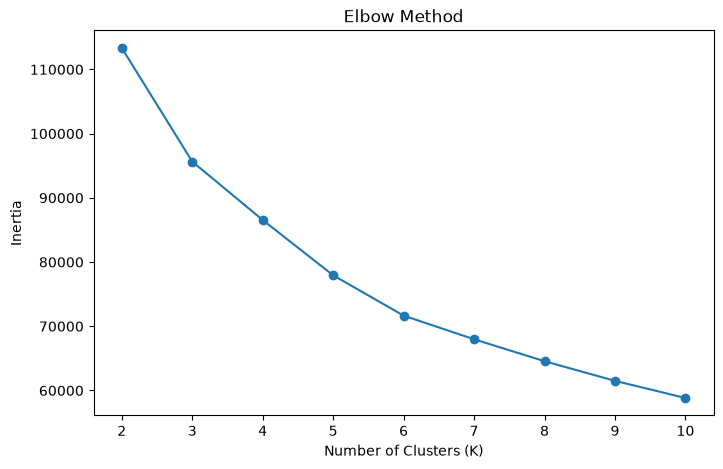

In [11]:
inertia = []

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(2, 11), inertia, marker='o')

plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.title('Elbow Method')
plt.show()

In [12]:
silhouette_scores = []

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X)

    score = silhouette_score(X, labels)
    silhouette_scores.append(score)

    print(f"K={k}, Silhouette Score={score:.4f}")

K=2, Silhouette Score=0.2515
K=3, Silhouette Score=0.2244
K=4, Silhouette Score=0.2166
K=5, Silhouette Score=0.2183
K=6, Silhouette Score=0.2172
K=7, Silhouette Score=0.2204
K=8, Silhouette Score=0.2100
K=9, Silhouette Score=0.1805
K=10, Silhouette Score=0.1817


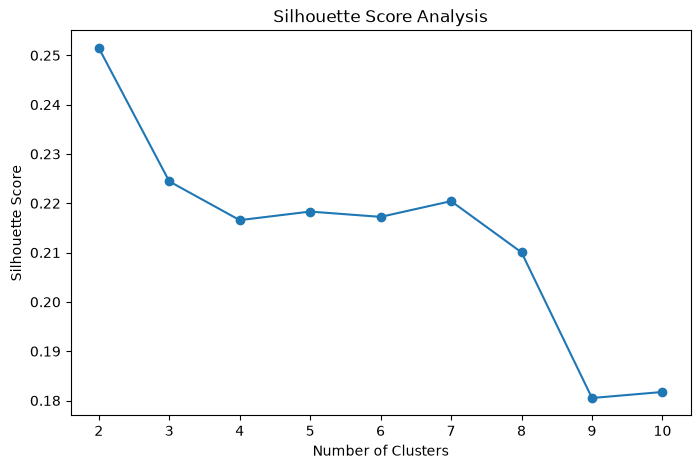

In [13]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 11),
    silhouette_scores,
    marker='o'
)

plt.xlabel('Number of Clusters')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score Analysis')
plt.show()

In [14]:
from sklearn.cluster import KMeans

kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

labels = kmeans.fit_predict(X)

print("Clustering completed!")

Clustering completed!


In [15]:
clustered = pd.read_csv('../data/credit_card.csv')

clustered['Cluster'] = labels

clustered.head()

,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE,Cluster
0,C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12,0
1,C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12,1
2,C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12,2
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12,0
4,C10005,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12,0


In [16]:
clustered['Cluster'].value_counts().sort_index()

Cluster
0    1570
1    2760
2    2580
3    2040
Name: count, dtype: int64

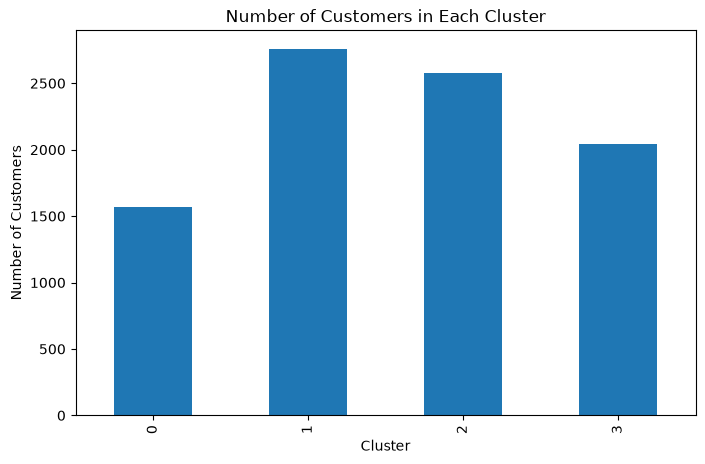

In [17]:
clustered['Cluster'].value_counts().sort_index().plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title('Number of Customers in Each Cluster')
plt.xlabel('Cluster')
plt.ylabel('Number of Customers')
plt.show()

In [18]:
cluster_profile = clustered.groupby('Cluster').mean(numeric_only=True)

cluster_profile.round(2)

,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
Cluster,,,,,,,,,,,,,,,,,
0,213.58,0.53,351.39,271.26,80.50,113.63,0.25,0.11,0.13,0.02,0.36,3.93,3561.53,742.55,167.52,0.16,11.33
1,2460.81,0.94,103.32,79.46,23.90,2220.06,0.07,0.04,0.03,0.30,7.37,1.21,4364.17,1818.29,1133.21,0.03,11.39
2,2243.73,0.98,2604.15,1751.80,852.41,862.92,0.82,0.55,0.55,0.11,2.87,35.47,6393.23,2933.03,1095.16,0.17,11.81
3,532.39,0.93,697.61,67.39,631.11,112.15,0.81,0.04,0.76,0.02,0.38,15.02,2986.83,862.81,666.20,0.29,11.45


In [19]:
clustered['Cluster'].value_counts(normalize=True).sort_index().mul(100).round(2)

Cluster
0    17.54
1    30.84
2    28.83
3    22.79
Name: proportion, dtype: float64

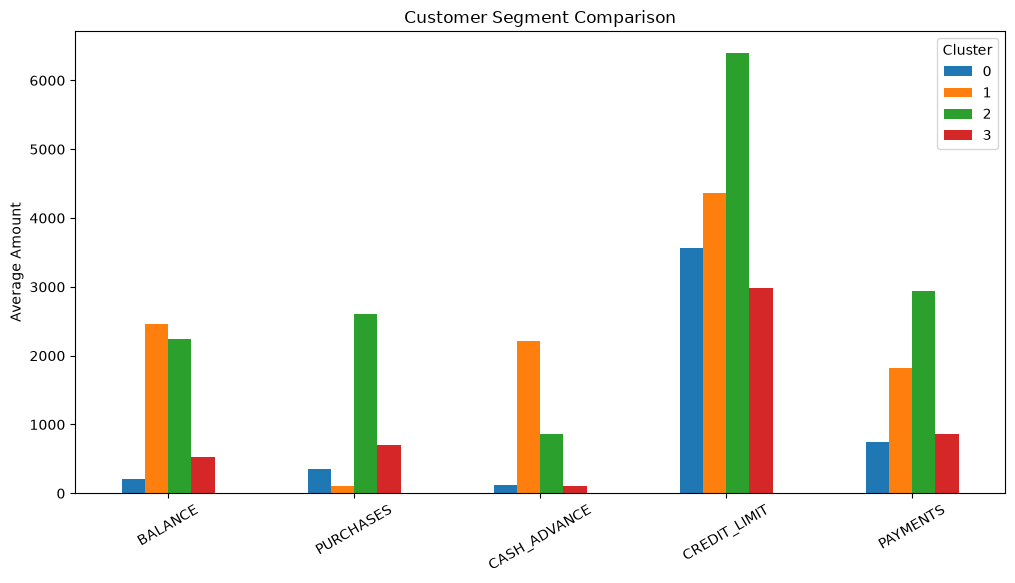

In [20]:
features = [
    'BALANCE',
    'PURCHASES',
    'CASH_ADVANCE',
    'CREDIT_LIMIT',
    'PAYMENTS'
]

cluster_profile[features].T.plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title('Customer Segment Comparison')
plt.ylabel('Average Amount')
plt.xticks(rotation=30)
plt.show()

In [21]:
important_features = [
    'BALANCE',
    'PURCHASES',
    'PURCHASES_FREQUENCY',
    'ONEOFF_PURCHASES',
    'INSTALLMENTS_PURCHASES',
    'CASH_ADVANCE',
    'CASH_ADVANCE_FREQUENCY',
    'CREDIT_LIMIT',
    'PAYMENTS',
    'PRC_FULL_PAYMENT',
    'TENURE'
]

cluster_profile = clustered.groupby('Cluster')[
    important_features
].mean().round(2)

cluster_profile

,BALANCE,PURCHASES,PURCHASES_FREQUENCY,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,CASH_ADVANCE_FREQUENCY,CREDIT_LIMIT,PAYMENTS,PRC_FULL_PAYMENT,TENURE
Cluster,,,,,,,,,,,
0,213.58,351.39,0.25,271.26,80.50,113.63,0.02,3561.53,742.55,0.16,11.33
1,2460.81,103.32,0.07,79.46,23.90,2220.06,0.30,4364.17,1818.29,0.03,11.39
2,2243.73,2604.15,0.82,1751.80,852.41,862.92,0.11,6393.23,2933.03,0.17,11.81
3,532.39,697.61,0.81,67.39,631.11,112.15,0.02,2986.83,862.81,0.29,11.45


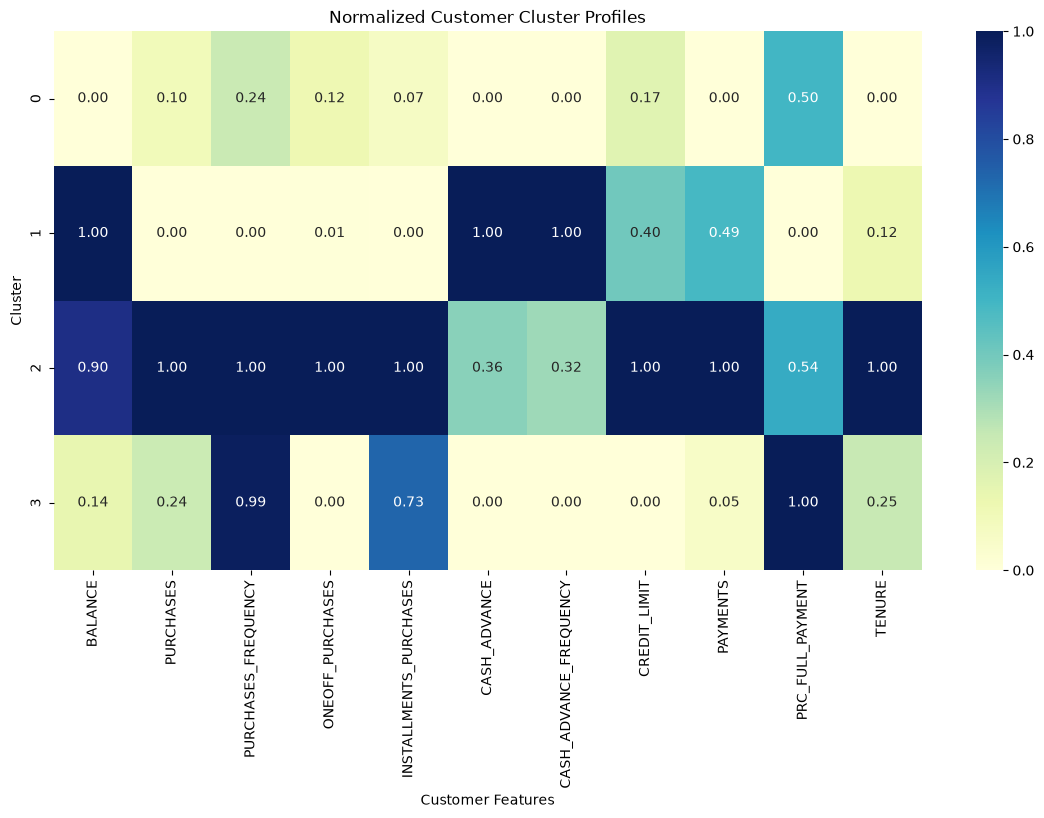

In [22]:
from sklearn.preprocessing import MinMaxScaler

profile_scaled = MinMaxScaler().fit_transform(cluster_profile)

profile_scaled = pd.DataFrame(
    profile_scaled,
    columns=cluster_profile.columns,
    index=cluster_profile.index
)

plt.figure(figsize=(14, 7))

sns.heatmap(
    profile_scaled,
    annot=True,
    cmap='YlGnBu',
    fmt='.2f'
)

plt.title('Normalized Customer Cluster Profiles')
plt.xlabel('Customer Features')
plt.ylabel('Cluster')

plt.show()

## Business Recommendations

### Cluster 0 – Low Engagement Customers
- Offer cashback incentives.
- Encourage regular credit card usage.
- Introduce purchase reward programs.

### Cluster 1 – Cash Advance Users
- Promote alternative payment options.
- Offer financial education.
- Encourage responsible credit usage.

### Cluster 2 – High Value Customers
- Offer premium credit cards.
- Provide exclusive rewards.
- Introduce loyalty programs.

### Cluster 3 – Frequent Installment Shoppers
- Offer installment-based promotions.
- Provide flexible EMI options.
- Introduce purchase-based rewards.

In [23]:
from sklearn.decomposition import PCA

In [24]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X)

print("Explained Variance Ratio:", pca.explained_variance_ratio_)
print("Total Variance:", pca.explained_variance_ratio_.sum())

Explained Variance Ratio: [0.33877054 0.21963864]
Total Variance: 0.5584091882770519


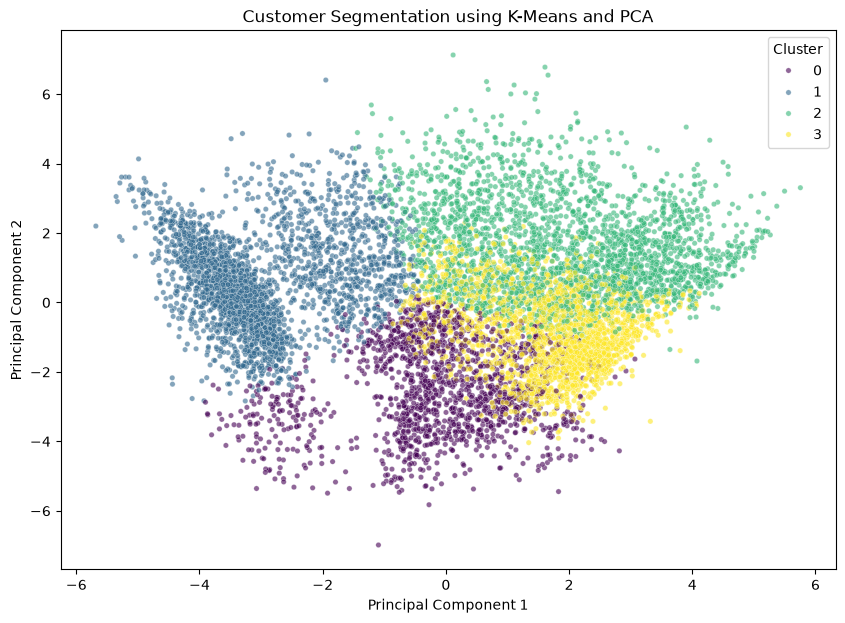

In [25]:
plt.figure(figsize=(10, 7))

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=labels,
    palette='viridis',
    s=15,
    alpha=0.6
)

plt.title('Customer Segmentation using K-Means and PCA')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Cluster')

plt.show()

In [26]:
from sklearn.cluster import AgglomerativeClustering

sample = X.sample(n=3000, random_state=42)

hierarchical = AgglomerativeClustering(n_clusters=4)

hier_labels = hierarchical.fit_predict(sample)

print("Hierarchical Silhouette:",
      silhouette_score(sample, hier_labels))

Hierarchical Silhouette: 0.16433447754542904


In [27]:
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(eps=1.5, min_samples=10)

db_labels = dbscan.fit_predict(sample)

print("DBSCAN clusters:", len(set(db_labels)) - (1 if -1 in db_labels else 0))
print("Noise points:", list(db_labels).count(-1))

if len(set(db_labels)) > 1 and len(set(db_labels)) < len(db_labels):
    print("DBSCAN Silhouette:",
          silhouette_score(sample, db_labels))

DBSCAN clusters: 8
Noise points: 974
DBSCAN Silhouette: -0.23524488969900706


In [29]:
import joblib

# Save trained models
joblib.dump(kmeans, '../models/kmeans_model.pkl')
joblib.dump(scaler, '../models/scaler.pkl')
joblib.dump(pca, '../models/pca_model.pkl')

# Save customer data with cluster labels
clustered.to_csv('../data/clustered_customers.csv', index=False)

# Save cluster profiles
cluster_profile.to_csv('../data/cluster_profiles.csv')

print("All project files saved!")

All project files saved!
